/Users/xqchen/workspace/doppler-imaging-maxentropy/venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Pre-computing some matrices... Done.
Compiling `spot`... Done.
Pre-computing some matrices... Done.
Compiling `set_matrix`... Done.
Compiling `enforce_shape`... Done.
Compiling `get_flux_from_dotconv`... Done.
Compiling `set_vector`... Done.
Compiling `render`... Done.


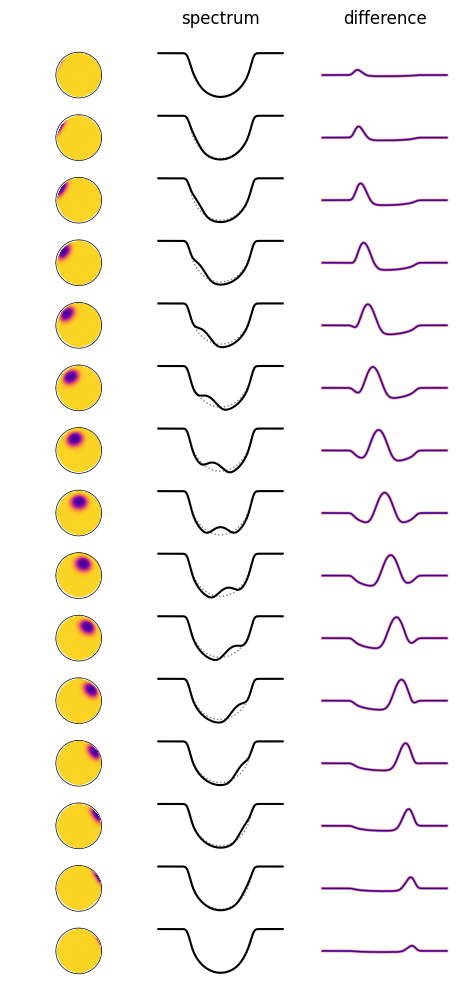

In [1]:
# -*- coding: utf-8 -*-
"""
Show the effect a rotating spot has on an absorption line.

"""
import matplotlib.pyplot as plt
import numpy as np
import starry

# Get the Ylm expansion of a Gaussian spot
ydeg = 20
N = (ydeg + 1) ** 2
spot_map = starry.Map(ydeg, lazy=False)
spot_map.spot(contrast=0.95, radius=20, lat=30, lon=0, spot_smoothing=0.125)
y = spot_map[:, :].reshape(-1)

# Generate the dataset
veq = 60000.0  # m/s
nt = 16
theta = np.append([-180], np.linspace(-90, 90, nt - 1))
map = starry.DopplerMap(
    ydeg, veq=veq, vsini_max=veq, inc=90, nt=nt, lazy=False
)
map[:, :] = y
map.spectrum = 1.0 - np.exp(-0.5 * (map.wav0 - 643.0) ** 2 / 0.0085 ** 2)
flux = map.flux(theta=theta)
F0 = flux[0]
F = flux[1:]

# Render the images
img = map.render(theta=theta[1:], res=300)
assert np.nanmin(img) > 0

# Set up the plot
fig, ax = plt.subplots(nt - 1, 3, figsize=(6, 12))
fig.subplots_adjust(hspace=0.3)
cmap = plt.get_cmap("plasma")
vmin = np.nanmin(img)
vmax = np.nanmax(img)
rng = vmax - vmin
vmin -= 0.1 * rng
vmax += 0.1 * rng

# Plot each spectrum
for t in range(nt - 1):

    # Plot spectrum
    ax[t, 1].plot(map.wav, F0, "k:", lw=1, alpha=0.5)
    ax[t, 1].plot(map.wav, F[t], "k-")
    ax[t, 1].axis("off")

    # Plot residuals
    color = [cmap(x) for x in np.linspace(0.75, 0.0, 5)]
    lw = np.linspace(2.5, 0.5, 5)
    alpha = np.linspace(0.25, 1, 5)
    for i in range(5):
        ax[t, 2].plot(
            map.wav,
            F[t] - F0,
            ls="-",
            lw=lw[i],
            color=color[i],
            alpha=alpha[i],
        )
    ax[t, 2].axis("off")
    ax[t, 2].set_ylim(-0.022, 0.022)

    # Plot current stellar image
    ax[t, 0].imshow(
        img[t],
        origin="lower",
        extent=(-1, 1, -1, 1),
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
    )
    x = np.linspace(-1, 1, 3000)
    y = np.sqrt(1 - x ** 2)
    ax[t, 0].plot(0.999 * x, 0.999 * y, "k-", lw=0.5, zorder=100)
    ax[t, 0].plot(0.999 * x, -0.999 * y, "k-", lw=0.5, zorder=100)
    ax[t, 0].set_xlim(-3, 1.05)
    ax[t, 0].set_ylim(-1.05, 1.05)
    ax[t, 0].axis("off")

ax[0, 1].set_title("spectrum", y=1.4)
ax[0, 2].set_title("difference", y=1.4)
fig.savefig("spot.pdf", bbox_inches="tight", dpi=300)